# Image Matching: A Small Comparison

Find matching points in an image pair, reject geometrically inconsistent matches,
and compare speed with matching evidence.

The four methods are **RootSIFT**, **SuperPoint + LightGlue**, **LoFTR** and **RoMa**.
The default is an offline CPU demo generated here, with known geometry.

Run cells from top to bottom. Keep `matching.py`, `compare.py` and `results.csv`
beside this notebook. Install base packages with `pip install -r requirements.txt`.
For neural methods, follow the optional installation commands in the README.
In Kaggle/Colab, upload these files together and enable GPU/Internet for neural models.


In [1]:
from pathlib import Path
import json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from compare import benchmark, make_demo

USE_DEMO = True
MODELS = ["sift"]  # Add "lightglue", "loftr", "roma" after installing dependencies.
LONG_SIDE = 640
NORMALIZE = False  # Compare on/off in separate runs using the same pairs.
REPEATS = 3
DEVICE = "auto"    # "cuda" to require GPU; "cpu" for CPU-only runs.
OUTPUT = Path("runs-demo")

# Used only when USE_DEMO is False. Paths are relative to this notebook.
PAIRS = [
    {"reference": "data/reference.jpg", "query": "data/query.jpg"}
]


## 1. Earlier results

These values are **rounded readings of an earlier experiment plot**. Raw pair
measurements and hardware details are unavailable. They illustrate a possible
speed/quality trade-off; they are not outputs of the code below.

JB3D pose success belongs to the earlier pose experiment. Our small runner uses
homography checks and does not calculate relative-pose success. SUES-200 has no
pose-success measurement in the supplied evidence.


,model,dataset,median_pair_ms_approx,pose_success_fraction_approx
0,SuperPoint + LightGlue,JB3D,60,0.42
1,SuperPoint + LightGlue,SUES-200,40,NaN
2,LoFTR,JB3D,165,0.50
3,LoFTR,SUES-200,170,NaN
4,RoMa,JB3D,810,0.67
5,RoMa,SUES-200,800,NaN


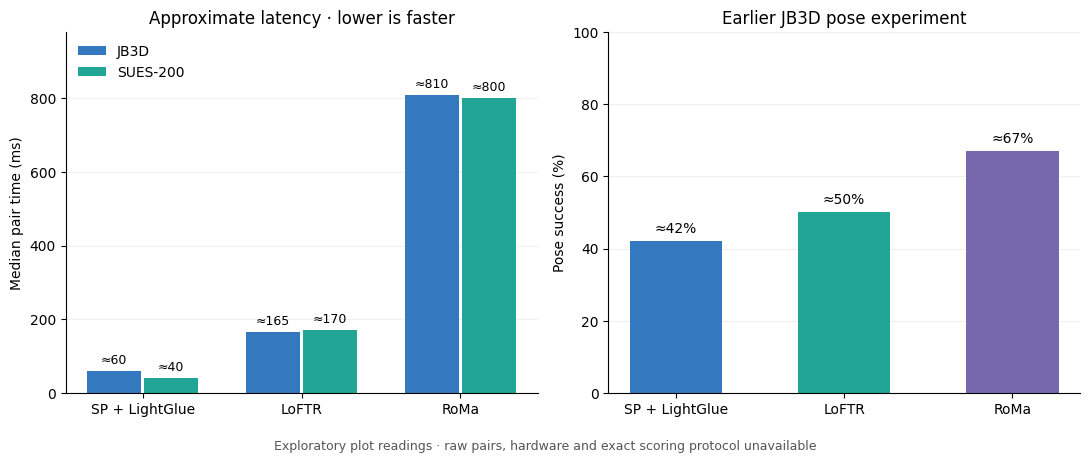

In [2]:
earlier = pd.read_csv("results.csv")
display(earlier[["model", "dataset", "median_pair_ms_approx", "pose_success_fraction_approx"]])

names = ["SuperPoint + LightGlue", "LoFTR", "RoMa"]
labels = ["SP + LightGlue", "LoFTR", "RoMa"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
x = np.arange(3)
for shift, dataset, color in [(-0.18, "JB3D", "#3478bf"), (0.18, "SUES-200", "#21a597")]:
    values = earlier[earlier.dataset == dataset].set_index("model").loc[names, "median_pair_ms_approx"]
    bars = axes[0].bar(x + shift, values, 0.34, color=color, label=dataset)
    axes[0].bar_label(bars, labels=[f"≈{v:g}" for v in values], padding=3, fontsize=9)
axes[0].set(xticks=x, xticklabels=labels, ylabel="Median pair time (ms)", ylim=(0, 980),
            title="Approximate latency · lower is faster")
axes[0].legend(frameon=False)
pose = earlier[earlier.dataset == "JB3D"].set_index("model").loc[names, "pose_success_fraction_approx"] * 100
bars = axes[1].bar(x, pose, 0.55, color=["#3478bf", "#21a597", "#7768ae"])
axes[1].bar_label(bars, labels=[f"≈{v:g}%" for v in pose], padding=4)
axes[1].set(xticks=x, xticklabels=labels, ylabel="Pose success (%)", ylim=(0, 100),
            title="Earlier JB3D pose experiment")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.yaxis.grid(True, alpha=0.18)
    ax.set_axisbelow(True)
fig.text(0.5, 0.01, "Exploratory plot readings · raw pairs, hardware and exact scoring protocol unavailable",
         ha="center", fontsize=9, color="#555555")
fig.tight_layout(rect=(0, 0.05, 1, 1))
OUTPUT.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT / "earlier_comparison.png", dpi=160)
plt.show()


## 2. Create inputs

The demo uses random shapes and text, followed by a perspective warp with a known
homography. A second pair darkens the warped image. A third pairs two independently
generated scenes as a negative control. This is a small implementation check,
not a representative real-world dataset.

For your own images, set `USE_DEMO = False` and edit `PAIRS`. An optional `H` is a
3×3 reference-to-query homography in **original** image pixels. The runner adjusts
it for resizing. For nonplanar scenes, a single homography may be inappropriate.


In [3]:
if USE_DEMO:
    reference, query, truth = make_demo(seed=7)
    unrelated, _, _ = make_demo(seed=19)
    dark_query = np.clip(query.astype(float) * 0.65, 0, 255).astype(np.uint8)
    for name, image in [("reference", reference), ("query", query),
                        ("dark_query", dark_query), ("unrelated", unrelated)]:
        cv2.imwrite(str(OUTPUT / f"{name}.png"), image)
    PAIRS = [
        {"reference": str(OUTPUT / "reference.png"), "query": str(OUTPUT / "query.png"), "H": truth.tolist()},
        {"reference": str(OUTPUT / "reference.png"), "query": str(OUTPUT / "dark_query.png"), "H": truth.tolist()},
        {"reference": str(OUTPUT / "reference.png"), "query": str(OUTPUT / "unrelated.png")},
    ]

print(f"{len(PAIRS)} pairs, {len(MODELS)} models, {REPEATS} repeats per pair")


3 pairs, 1 models, 3 repeats per pair


## 3. Match and verify

Every method uses MAGSAC homography estimation with a 3 px threshold.
The geometric gate requires at least 18 inliers, an inlier ratio of 0.20,
coverage of 0.005 in both images and a plausible transformed outline.

`pair_ms` includes feature extraction from both prepared images, matching and
geometry. Model loading, image reading, resizing, optional brightness adjustment,
truth scoring and plotting are excluded. One warm-up is excluded; each reported
pair time is the median of repeated calls. GPU timings synchronize CUDA.

The CSV retains failed inputs. Dependency and model/CUDA failures stop the run;
for a CUDA failure, restart the kernel before retrying.


In [4]:
rows = benchmark(PAIRS, models=MODELS, output=OUTPUT, long_side=LONG_SIDE,
                 normalize=NORMALIZE, device=DEVICE, repeats=REPEATS)
metrics = pd.DataFrame(rows)
display(metrics[["model", "pair", "status", "matches", "inliers", "inlier_ratio",
                 "geometry_pass", "reason", "pair_ms", "corner_error_px"]])


,model,pair,status,matches,inliers,inlier_ratio,geometry_pass,reason,pair_ms,corner_error_px
0,sift,0,ok,380,341,0.897368,True,passed,64.350175,0.111180
1,sift,1,ok,351,316,0.900285,True,passed,77.927570,0.080543
2,sift,2,ok,124,48,0.387097,True,passed,88.754356,NaN


## 4. Inspect the results

Green lines below agree with the estimated homography; red lines are outliers.
Geometric agreement can still be wrong for repeated structures. Look at the
actual correspondences instead of relying on a match count.

`geometry_pass` is a diagnostic gate, **not accuracy**. `corner_error_px` is a
mean error against known homography corners, in resized query pixels. It is empty
when ground truth or an estimated homography is unavailable. Input-error rows
remain in counts; their timing is not treated as zero.


**False-positive example:** the saved RootSIFT CPU run also accepts pair 2,
even though its scenes are independently generated. They reuse the same printed
labels, producing geometrically consistent but misleading correspondences.
This demonstrates why passing the gate is not sufficient for scene recognition.


Pairs 0 and 1: true warped correspondence. Pair 2: negative control.
Negative control: inspect matches to the repeated printed labels.
Run settings:
{
  "python": "3.12.14",
  "platform": "Linux-6.18.44-x86_64-with-glibc2.39",
  "versions": {
    "numpy": "2.2.6",
    "opencv-python-headless": "4.12.0.88"
  },
  "long_side": 640,
  "normalize": false,
  "normalization_strength": 0.0,
  "repeats": 3,
  "seed": 7,
  "models": {
    "sift": {
      "max_keypoints": 2048,
      "ratio_threshold": 0.8,
      "descriptor": "RootSIFT",
      "device": "cpu",
      "model_load_s": 3.9548999893668224e-05
    }
  },
  "geometry": {
    "method": "USAC_MAGSAC",
    "threshold_px": 3.0,
    "min_inliers": 18,
    "min_ratio": 0.2,
    "min_coverage": 0.005
  }
}



,requested_pairs,completed_pairs,geometry_passes,median_pair_ms,median_corner_error_px
model,,,,,
sift,3,3,3,77.92757,0.095861


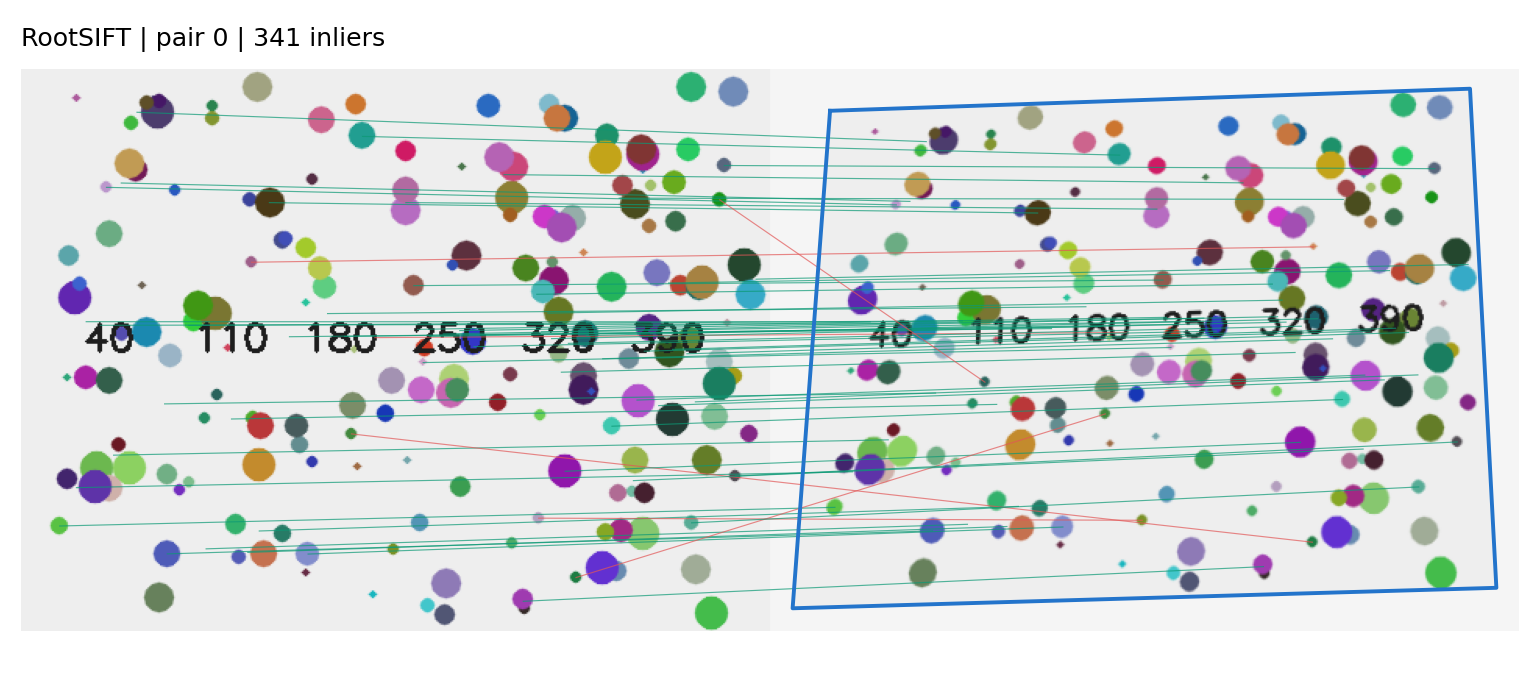

,model,pair,geometry_pass,reason
0,sift,0,True,passed
1,sift,1,True,passed
2,sift,2,True,passed


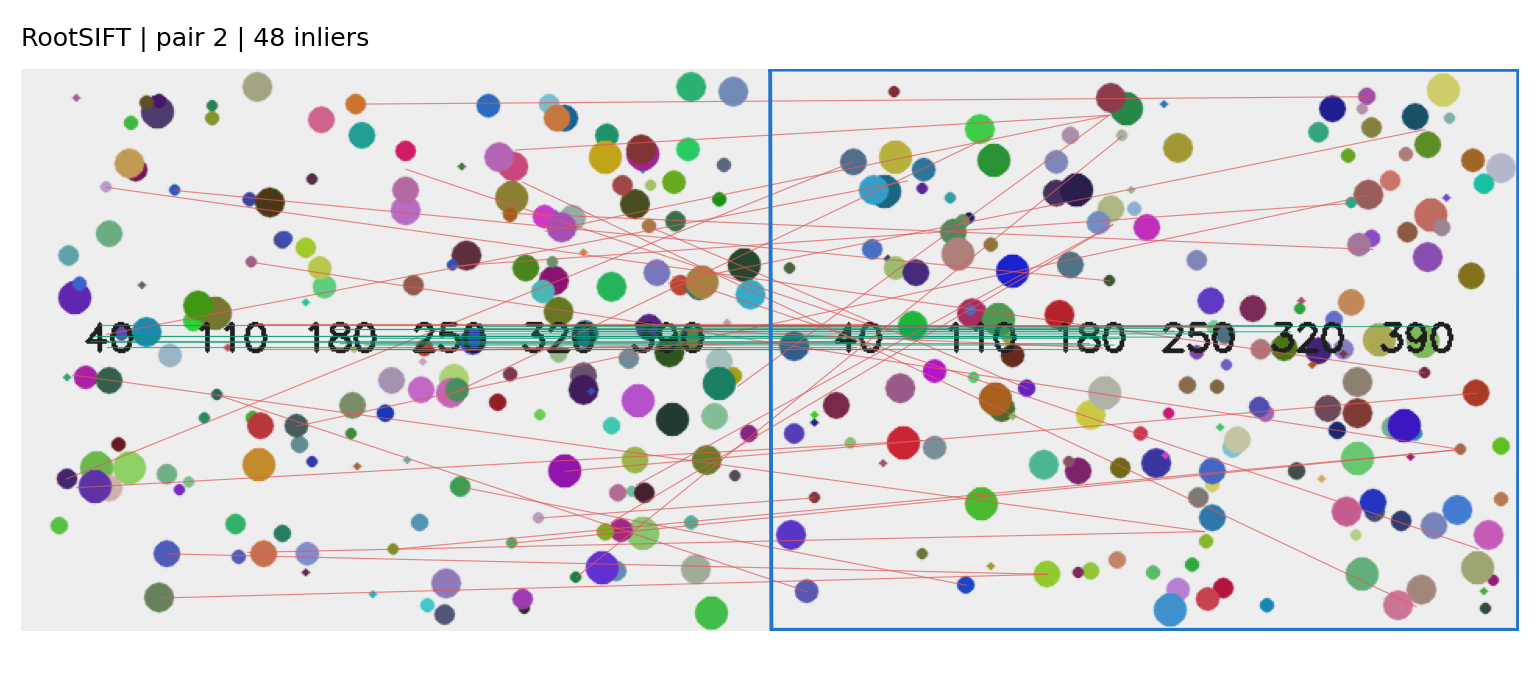

In [5]:
summary = metrics.groupby("model").agg(
    requested_pairs=("pair", "size"),
    completed_pairs=("status", lambda x: (x == "ok").sum()),
    geometry_passes=("geometry_pass", "sum"),
    median_pair_ms=("pair_ms", "median"),
    median_corner_error_px=("corner_error_px", "median"),
)
display(summary)
for kind in MODELS:
    path = OUTPUT / f"{kind}_000.png"
    if path.exists():
        display(Image(filename=str(path)))

if USE_DEMO:
    print("Pairs 0 and 1: true warped correspondence. Pair 2: negative control.")
    display(metrics[["model", "pair", "geometry_pass", "reason"]])
if USE_DEMO and "sift" in MODELS:
    print("Negative control: inspect matches to the repeated printed labels.")
    display(Image(filename=str(OUTPUT / "sift_002.png")))
print("Run settings:")
print((OUTPUT / "run.json").read_text())


## Takeaways

- Earlier results suggest LightGlue is faster, while RoMa trades latency for
  higher pose success on that particular test. The limited evidence does not
  establish a universal ranking.
- More correspondences are useful only when they cover the image and support
  the right geometry. Repeated patterns can produce misleading inliers.
- Brightness adjustment should be evaluated on the same pairs with and without
  correction. It cannot recover unseen surfaces or missing overlap.
- To extend this experiment, use public pairs with independent ground truth,
  include negative pairs, report failures and save your settings. A planar
  synthetic example alone cannot establish real-world performance.

The generated demo has been run on CPU with RootSIFT. Neural inference requires
its optional packages and weights; the saved demo outputs do not evaluate the
neural methods. All displayed files are generated or aggregate data. No original
private images, paths or notebook outputs are included.
